# MixBench experiment and test report

How many shuffles does it take before the starting deck stops being useful for prediction? A random walk on a graph has the same problem. We tested changes to the move probabilities, added direction memory on a line, and tried shortcuts on different networks. We also checked whether a faster-mixing walk gives a more accurate estimate from a single trajectory.

**Three results to look for**

- On the 100-position line, direction memory reached the position cutoff in **141 steps**, compared with **1,898** for the two ordinary walks that were measured.
- On the karate club network, optimized weights helped the slowest start most. Metropolis led for the median start.
- A shortcut cut the 32-position ring from **195 to 61 steps**. The same shortcut increased the error of estimating how often a trajectory visits half the ring.

Read down for the methods, the sixteen verification suites, and the figures and tables. The [report PDF](../output/pdf/mixbench-experiment-report.pdf) gives the same story in a format you can share.

## Running the notebook

Use a Jupyter kernel with [requirements.txt](../requirements.txt) installed, then select **Run All**. The notebook configures a release build with that kernel's Python interpreter. The [build instructions](../README.md) list the C++ dependencies. Displaying the vector plots as inline images also uses Poppler's `pdftoppm`.

**Review mode** builds and tests the code, computes the riffle curve, and replays the five-vertex, clockwise ring, bridge, and small real-network comparisons. The larger sweeps and timed plots come from the measurements in the report. Each table or figure identifies its source.

Set the mode to **full** to replay all graph presets, generate fresh figures, and run the longer independent reference checks. The timed sweep can also be enabled. It has 105 trials of up to 60 seconds each and takes about 105 minutes serially. Restart the kernel before changing settings. Point `MIXBENCH_RESULTS` at a fresh directory to force new measurements in place of reusing complete matching runs.

In [1]:
from pathlib import Path
import os
import sys

mode = os.environ.get("MIXBENCH_NOTEBOOK_MODE", "review")   # "review" or "full"
run_timed = os.environ.get("MIXBENCH_RUN_TIMED", "0") == "1" # full mode only
jobs = int(os.environ.get("MIXBENCH_JOBS", "4"))

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "experiments" / "reproduce.json").is_file())
os.environ.setdefault("MIXBENCH_RESULTS", str(root / "results" / "notebook" / mode))
os.environ["MIXBENCH_FIGURE_DIR"] = str(Path(os.environ["MIXBENCH_RESULTS"]).resolve() / "figures/replayed")
sys.path.insert(0, str(root / "scripts"))

if mode not in {"review", "full"} or (run_timed and mode != "full"):
    raise ValueError("Choose review or full mode. Timed runs require full mode.")

from importlib.util import find_spec
from shutil import which

missing = [name for name in ("numpy", "scipy", "matplotlib") if find_spec(name) is None]
if missing:
    raise RuntimeError(f"Install requirements.txt in this kernel. Missing: {', '.join(missing)}")
if which("pdftoppm") is None:
    raise RuntimeError("Install Poppler so pdftoppm can render the notebook figures.")

from notebook_runs import EXE, OUT, run_preset, run_budget, single_thread_env
from notebook_reports import release_tests, report, show_plot, show_table

print(f"Mode: {mode}. Output: {os.path.relpath(OUT, root)}")

Mode: review. Output: results/notebook/review


## What counts as mixed?

> **Student credit** · Danielle explored optimized weights, Dana studied direction memory, Caroline tested ring shortcuts, and Aditi compared rules for choosing one new link.

The target gives every deck order or graph vertex the same probability. **Total variation (TV)** is the largest gap between the current probability and the target probability of any event. At TV 0.25, the probability of any event, such as being in the left half of a line, is within 25 percentage points of its target.

To measure mixing, we put all probability at one start, then pass that probability along the links at each step. If a vertex holds 40% of the total probability and takes a link with chance 1/4, it sends 10% of the total along that link. We repeat the calculation for the chosen starts. The reported crossing is the first step at which all tested starts meet the cutoff, usually TV 0.25. The full grid and the repeated link-policy trials use sampled starts. These sample maxima can be below the all-start maximum.

| Method | What changes |
| --- | --- |
| Maximum degree | Use one link probability, 1 divided by the largest neighbor count on the graph. Spend the rest on staying put. |
| Metropolis | Use the same idea locally, taking the larger neighbor count at a link's two endpoints. |
| Optimized weights | Hold the graph fixed. Choose symmetric link probabilities to shrink the slowest lingering probability imbalance. |
| Direction memory | Give each position two states, one for each heading. The walker usually keeps going in its current direction. Combine the two headings to measure position alone. |
| Clockwise shortcut | Keep the clockwise step at 1/2 and add a two-way jump with probability 1/4 at its endpoints. The remaining probability stays at the current vertex. |
| One-link selection | Try a random link, a link from a vertex with fewest neighbors, the Fiedler rule, or a search over every missing link for the largest connectivity gain. |

A **transition eigenvalue** tells us how much of a particular probability imbalance survives one step. A magnitude of 0.9 leaves 90% after a step. **Algebraic connectivity** uses the links themselves and captures how weakly groups of vertices may be joined. The **Fiedler vector** gives one coordinate to each vertex from that graph calculation. The Fiedler rule joins an eligible pair far apart in those coordinates, often putting a new link across a bottleneck.

## What the tests check

> **Student credit** · The independent reference checks compare the lifted walk with Dana’s implementation, the optimized weights with Danielle’s, and the ring placements with Caroline’s. The link-policy regression replays Aditi’s experiments.

The verification suites check different parts of the same pipeline. Independent calculations catch mistakes in the walk itself, such as lost probability or an incorrect crossing time. Experiment checks catch mismatches in the graph, starts, links or trial pairing. Output checks verify that reports represent missing and periodic crossings correctly.

The table describes every CTest suite and reports whether it passed. The runtime chart measures the test workload on the current machine. The notebook saves the table, the chart, the complete console log, and machine-readable JUnit results.

16 of 16 CTest suites passed.


| Suite | What it checks | Result | Seconds |
| --- | --- | --- | --- |
| core | Checks known transition probabilities and eigenvalues, and compares ring and lifted-path crossings with independent calculations. | Passed | 0.048 |
| cli | Checks that serial and parallel runs agree, verifies dataset checksums, and checks periodic and size-limit records. | Passed | 0.147 |
| studies_edge_ranking | Checks missing-link ranks, equal winners, and when the connectivity and mixing objectives agree. | Passed | 0.088 |
| studies_path_oracle | Checks the analytic path eigenvalues and confirms that both walks start at the same physical endpoint. | Passed | 0.085 |
| studies_nested_networks | Checks that each larger graph keeps the smaller sample and every original link between the selected vertices. | Passed | 0.127 |
| studies_wall_budget | Checks matched starts, deadline observations, and the error summaries for timed estimates. | Passed | 0.166 |
| riffle | Checks exact shuffle counts against explicit small decks and the 52-card reference values. | Passed | 0.113 |
| bridges | Checks disjoint bridge placement, probability sums, and a known eigenvalue on the two-group graph. | Passed | 0.133 |
| budget_repetitions | Checks that the serial and partitioned timed schedules use the same graphs, seeds, chosen edges and trial order. | Passed | 0.594 |
| link_policy_trials | Replays fixed graphs and verifies the selected links, matched starts, connectivity and crossings against archived trials. | Passed | 15.175 |
| power_grid | Checks sparse power-grid probability propagation against an independent calculation. | Passed | 29.416 |
| dana_parity | Checks lifted-path matrices and finite-size probability curves against the original Python implementation. | Passed | 0.399 |
| dhn | Checks heading changes, position-only and full-state distances, and seeded sampling on the lifted path. | Passed | 0.759 |
| real_networks | Checks Glasgow and karate-club walks by dense propagation, including the optimized transition weights. | Passed | 9.187 |
| edge_policies | Checks whether chosen links are eligible and whether exhaustive search reaches the best connectivity score. | Passed | 0.887 |
| plots | Checks tables and figures for matched and mismatched starts, unreachable thresholds, and an immediate crossing. | Passed | 13.489 |

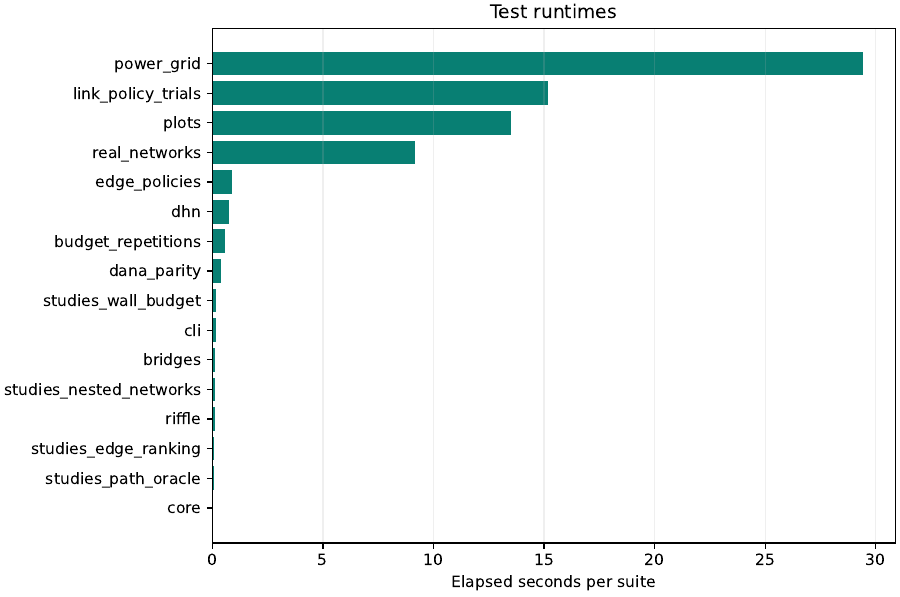

In [2]:
checks = {
    "core": "Checks known transition probabilities and eigenvalues, and compares ring and lifted-path crossings with independent calculations.",
    "cli": "Checks that serial and parallel runs agree, verifies dataset checksums, and checks periodic and size-limit records.",
    "studies_edge_ranking": "Checks missing-link ranks, equal winners, and when the connectivity and mixing objectives agree.",
    "studies_path_oracle": "Checks the analytic path eigenvalues and confirms that both walks start at the same physical endpoint.",
    "studies_nested_networks": "Checks that each larger graph keeps the smaller sample and every original link between the selected vertices.",
    "studies_wall_budget": "Checks matched starts, deadline observations, and the error summaries for timed estimates.",
    "riffle": "Checks exact shuffle counts against explicit small decks and the 52-card reference values.",
    "bridges": "Checks disjoint bridge placement, probability sums, and a known eigenvalue on the two-group graph.",
    "budget_repetitions": "Checks that the serial and partitioned timed schedules use the same graphs, seeds, chosen edges and trial order.",
    "link_policy_trials": "Replays fixed graphs and verifies the selected links, matched starts, connectivity and crossings against archived trials.",
    "power_grid": "Checks sparse power-grid probability propagation against an independent calculation.",
    "dana_parity": "Checks lifted-path matrices and finite-size probability curves against the original Python implementation.",
    "dhn": "Checks heading changes, position-only and full-state distances, and seeded sampling on the lifted path.",
    "real_networks": "Checks Glasgow and karate-club walks by dense propagation, including the optimized transition weights.",
    "edge_policies": "Checks whether chosen links are eligible and whether exhaustive search reaches the best connectivity score.",
    "plots": "Checks tables and figures for matched and mismatched starts, unreachable thresholds, and an immediate crossing.",
}
release_tests(checks)

## Card shuffling

A riffle cuts a deck into two packets and interleaves them while preserving the order inside each packet. Repeating the shuffle is a random walk through possible deck orders. We can count the probabilities exactly for the standard random riffle, so the curve is free of simulation error. Seven riffles leave TV about 0.334, while eight leave about 0.167. Eight is the first crossing of TV 0.25. [Bayer and Diaconis (1992)](https://www.stat.berkeley.edu/~aldous/157/Papers/bayer_diaconis.pdf)

| Riffles | TV |
| --- | --- |
| 5 | 0.9237 |
| 6 | 0.6135 |
| 7 | 0.3341 |
| 8 | 0.1672 |
| 9 | 0.0854 |
| 10 | 0.0429 |
| 11 | 0.0215 |
| 12 | 0.0108 |

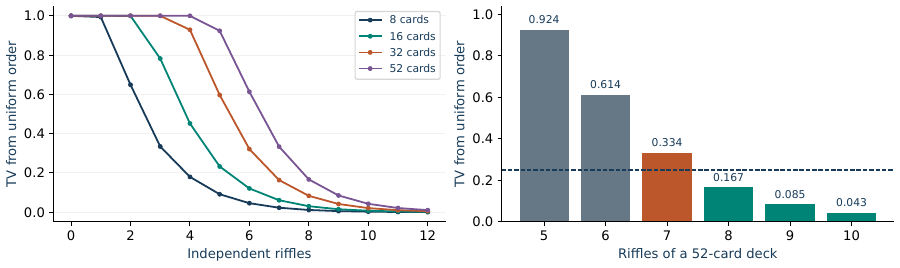

In [3]:
from comparison_stats import write_csv
from riffle import riffle_tv
from presentation_figures import FIG, riffle

shuffle = [dict(cards=n, shuffles=k, tv=float(riffle_tv(n, k)))
           for n in (4, 8, 16, 32, 52) for k in range(13)]
write_csv(OUT / "riffle.csv", shuffle)
show_table("52-card-riffles", [{"Riffles": r["shuffles"], "TV": round(r["tv"], 4)}
                             for r in shuffle if r["cards"] == 52 and r["shuffles"] >= 5])
riffle()
show_plot(FIG / "riffle.pdf", "replayed")

## Replaying the graph experiments

The next cell saves the case records and prints the run counts. The comparison sections below explain the results in context. A replay can reuse an existing complete run if its configuration still matches.

In full mode, the notebook also checks the six original lifted-path sizes, compares the five-vertex weights and ring results with the original implementations, checks the solver output for the difficult chorded ring, and writes a combined inventory and case table.

In [4]:
import csv
import subprocess
from statistics import median

from presentation_figures import glasgow_map, make_figures, placement, start_effects

quick = ["reproduce", "cycle-placement", "matched-ring-links", "bridge-count", "real-networks"]
names = (sorted(p.stem for p in (root / "experiments").glob("*.json") if p.stem != "wall-budget")
         if mode == "full" else quick)
measured = {}
for name in names:
    print(f"\n{name}")
    measured[name] = report(run_preset(name, 1 if name == "mcmc" else jobs))
if run_timed:
    run_budget()
    names.append("wall-budget")

if mode == "full":
    from audit_results import audit
    from compare_results import combine
    from student_parity import verify_students

    env = single_thread_env()
    with (OUT / "dana-parity.csv").open("w") as output:
        subprocess.run([sys.executable, "-B", root / "scripts/verify_dana.py",
                        "--exe", EXE, "--jobs", "2"], env=env, stdout=output, check=True)
    checks_from_reference = verify_students(OUT / "reproduce", OUT)
    print("Independent reference checks:", checks_from_reference)
    inventory = audit(OUT, presets=names)
    combine(OUT / "comparisons", [OUT / row["preset"] for row in inventory])
    hard = next((r for r in measured["method-scaling"]
                 if r["vertices"] == 64 and r["method"] == "fmmc" and r["edge"] == [51, 63]), None)
    command = [sys.executable, "-B", root / "tests/solver_retry.py"]
    if hard is not None:
        command += ["--run-json", OUT / "method-scaling" / f"run-{hard['run']}.json"]
    check = subprocess.check_output(command, text=True, env=env)
    (OUT / "solver-check.log").write_text(check)
    make_figures(include_budget=run_timed)
else:
    placement()
    glasgow_map()
    start_effects()

def figures(*names):
    for name in names:
        replayed = (mode == "full" and (name != "budget" or run_timed)) or name in {
            "glasgow-map", "placement", "starts",
        }
        source = FIG if replayed else root / "presentation" / "figures"
        edition = "replayed" if replayed else "report"
        print(f"{name.replace('-', ' ').title()} ({'replay' if replayed else 'report measurements'})")
        show_plot(source / f"{name}.pdf", edition)

def tv_rows(name, eps=.25, space="full"):
    return [r for r in measured[name] if r.get("epsilon") == eps and r["space"] == space]

def csv_rows(path):
    with path.open() as handle:
        return list(csv.DictReader(handle))

labels = {"clockwise": "Clockwise", "max_degree": "Maximum degree", "metropolis": "Metropolis",
          "fmmc": "Optimized weights", "dhn": "Lifted"}


reproduce
33 runs in "results/notebook/review/reproduce"
reproduce: 33 records, 2 graphs
Crossings and skip records: {'resolved': 33}
  Danielle K2,3 (n=5) max_degree / full: 3 (all starts)
  Danielle K2,3 (n=5) metropolis / full: 3 (all starts)
  Danielle K2,3 (n=5) fmmc / full: 2 (all starts)
  Caroline placement (n=32) clockwise / full: 195 (all starts)

cycle-placement
30 runs in "results/notebook/review/cycle-placement"
cycle-placement: 30 records, 1 graphs
Crossings and skip records: {'resolved': 30}
  Cycle placement (n=32) clockwise / full: 195 (all starts)

matched-ring-links


73 runs in "results/notebook/review/matched-ring-links"
matched-ring-links: 73 records, 1 graphs
Crossings and skip records: {'resolved': 73}
  Matched one-link policies on a clockwise ring (n=32) clockwise / full: 195 (all starts)

bridge-count
12 runs in "results/notebook/review/bridge-count"
bridge-count: 12 records, 4 graphs
Crossings and skip records: {'resolved': 48}
  1 bridge (n=16) max_degree / full: 28 (all starts)
  1 bridge (n=16) metropolis / full: 28 (all starts)
  1 bridge (n=16) fmmc / full: 15 (all starts)
  2 bridges (n=16) max_degree / full: 14 (all starts)
  2 bridges (n=16) metropolis / full: 14 (all starts)
  2 bridges (n=16) fmmc / full: 7 (all starts)
  4 bridges (n=16) max_degree / full: 7 (all starts)
  4 bridges (n=16) metropolis / full: 7 (all starts)

real-networks


17 runs in "results/notebook/review/real-networks"
real-networks: 17 records, 2 graphs
Crossings and skip records: {'resolved': 68}
  Glasgow ring (n=15) clockwise / full: 43 (all starts)
  Glasgow ring (n=15) max_degree / full: 43 (all starts)
  Glasgow ring (n=15) metropolis / full: 43 (all starts)
  Glasgow ring (n=15) fmmc / full: 14 (all starts)
  Karate club (n=34) max_degree / full: 48 (all starts)
  Karate club (n=34) metropolis / full: 35 (all starts)
  Karate club (n=34) fmmc / full: 26 (all starts)


## Weights on a fixed graph

> **Student credit** · Danielle’s optimized weights motivate the five-vertex and karate-club comparisons.

The five-vertex example joins each of two vertices to each of three others. Optimization changes the probability of taking each link from 1/3 to 2/7. At a vertex with three links, the chance of staying rises from zero to 1/7. This lowers the slowest decay factor from 2/3 to 3/7 and reduces the TV crossing from three steps to two. [Boyd, Diaconis and Xiao (2004)](https://web.stanford.edu/~boyd/papers/fmmc.html)

The karate club graph records friendship ties among 34 members. We tested the same original graph and every starting vertex with all three weight rules. In the ranked-start plot, the middle indicates a typical start and the right edge indicates the slowest. The optimized weights help the slowest start most, while Metropolis leads for the median. [Zachary (1977)](https://doi.org/10.1086/jar.33.4.3629752)

| Graph | Weight rule | Slowest start (steps) | Median start (steps) |
| --- | --- | --- | --- |
| Danielle K2,3 | Maximum degree | 3 | 2.0 |
| Danielle K2,3 | Metropolis | 3 | 2.0 |
| Danielle K2,3 | Optimized weights | 2 | 2.0 |
| Karate club | Maximum degree | 48 | 21.0 |
| Karate club | Metropolis | 35 | 15.0 |
| Karate club | Optimized weights | 26 | 21.5 |

Starts (replay)


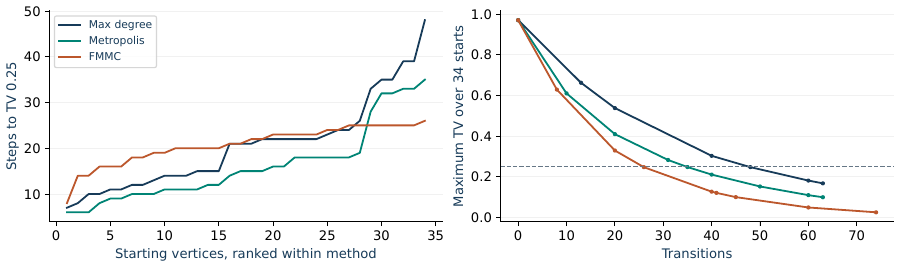

In [5]:
show_table("fixed-graph-weights", [
    {"Graph": r["study"], "Weight rule": labels[r["method"]],
     "Slowest start (steps)": r["steps"], "Median start (steps)": r["start_median"]}
    for name, n in [("reproduce", 5), ("real-networks", 34)] for r in tv_rows(name)
    if r["vertices"] == n and r["edge"] is None
])
figures("starts")

## Direction memory on a line

> **Student credit** · Dana’s lifted walk is compared with ordinary and optimized weight rules, including the approach studied by Danielle.

The ordinary walk may undo much of its progress by moving back and forth. The lifted walk stores its heading and usually continues in that direction. At the end it turns around, with occasional reversals along the line. We compared both initial headings at each start, then added their probabilities when observing position alone. Full-state TV also tracks the heading. [Diaconis, Holmes and Neal (2000)](https://projecteuclid.org/euclid.aoap/1019487508)

The main table uses every start and TV 0.25. The scaling plot uses a different setup, with one matched endpoint and the tighter TV 0.10 cutoff. At 512 positions, the lifted walk took 1,227 steps and maximum degree took 98,328. Over these sizes, doubling the path roughly doubled the lifted time and quadrupled the ordinary time.

Table source: report measurements


| Positions | Maximum degree | Metropolis | Optimized | Lifted position | Lifted full state |
| --- | --- | --- | --- | --- | --- |
| 10 | 19 | 19 | 19 | 13 | 14 |
| 20 | 76 | 76 | 76 | 27 | 30 |
| 50 | 474 | 474 | 474 | 70 | 77 |
| 100 | 1898 | 1898 | Size cap | 141 | 155 |

Path (report measurements)


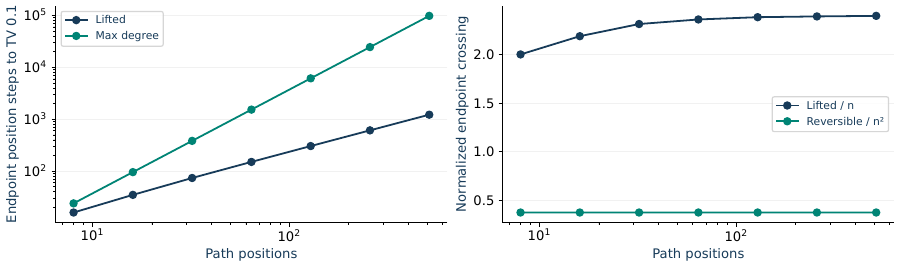

In [6]:
if mode == "full":
    hits = {(r["vertices"], r["method"], r.get("space")): r.get("steps")
            for r in measured["path-comparison"] if r.get("epsilon") in (.25, None)}
    path = [
        (n, hits[n, "max_degree", "full"], hits[n, "metropolis", "full"],
         hits.get((n, "fmmc", "full"), "Size cap"), hits[n, "dhn", "position"], hits[n, "dhn", "full"])
        for n in (10, 20, 50, 100)
    ]
else:
    path = [(10, 19, 19, 19, 13, 14), (20, 76, 76, 76, 27, 30),
            (50, 474, 474, 474, 70, 77), (100, 1898, 1898, "Size cap", 141, 155)]
columns = ["Positions", "Maximum degree", "Metropolis", "Optimized", "Lifted position", "Lifted full state"]
print("Table source:", "replay" if mode == "full" else "report measurements")
show_table("path-comparison", [dict(zip(columns, values, strict=True)) for values in path])
figures("path")

## Shortcuts on rings and between groups

> **Student credit** · Caroline’s ring shortcut and Aditi’s one-link policies are tested on the same clockwise ring. The bridge and tree comparisons continue the link-selection study.

On an unedited ring a concentration of probability can travel around together. A two-way shortcut sends some of that concentration to another part of the circle. On a 32-position ring we fixed one end, tried all 29 eligible partners and included all starts. Five placements tied at 61 steps, with 195 steps for the unedited ring. At 256 positions the opposite-side link took 3,109 steps, while the six random draws ranged from 1,086 to 9,393. Placement matters more than the mere presence of a link. [Gerencsér (2019)](https://arxiv.org/abs/1905.03223)

The link-policy table holds the graph, clockwise rule and starting positions fixed. All 29 candidates tie on the connectivity score. The exhaustive connectivity rule picks the first tied link, so its selected shortcut can mix much more slowly than another member of the same tie.

| Policy | Draws | Median steps | Min | Max |
| --- | --- | --- | --- | --- |
| Original ring | 1 | 195 | 195 | 195 |
| Opposite-side link | 1 | 61 | 61 | 61 |
| Fiedler | 1 | 63 | 63 | 63 |
| Random | 20 | 71.5 | 61 | 151 |
| Fewest neighbors | 20 | 64.0 | 61 | 172 |
| Exhaustive connectivity | 1 | 172 | 172 | 172 |

Placement (replay)


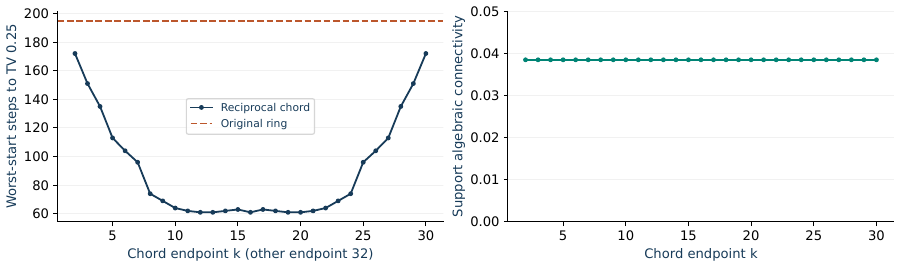

Cycle Scaling (report measurements)


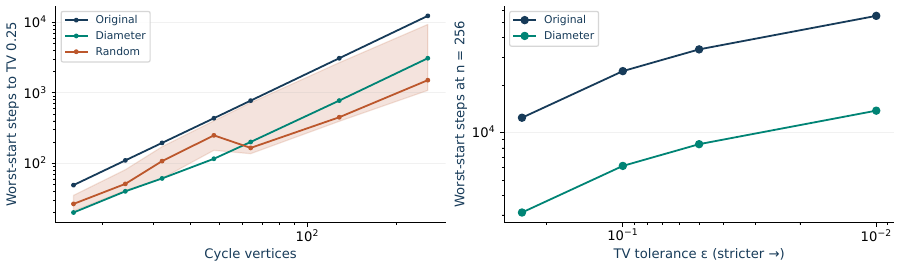

In [7]:
policy_labels = {"none": "Original ring", "halves": "Opposite-side link", "fiedler": "Fiedler",
                 "random": "Random", "min_degree": "Fewest neighbors",
                 "optimal_connectivity": "Exhaustive connectivity"}
ring_rows = tv_rows("matched-ring-links")
show_table("matched-ring-links", [
    {"Policy": text, "Draws": len(steps), "Median steps": median(steps),
     "Min": min(steps), "Max": max(steps)}
    for policy, text in policy_labels.items()
    if (steps := [r["steps"] for r in ring_rows if r["policy"] == policy])
])
figures("placement", "cycle-scaling")

### When connectivity helps choose an edge

Two dense groups joined by one bridge give a bottleneck. Adding more disjoint bridges reduced the crossing and narrowed the gap between weight rules. In a separate exhaustive search on two groups of six, all 25 links with the best connectivity were also among the fastest for mixing. On the karate club, the objectives shared one winner. On the 12-position clockwise ring, connectivity tied all 54 candidate links and only six gave the fastest crossing.

On the 255-vertex tree the Fiedler rule shortened the sampled-start crossing from 517 to 501. Some other links raised the largest neighbor count from three to four, so the maximum-degree baseline decreased every link's move probability from 1/3 to 1/4 and the walk slowed. The smaller dense graphs already mixed in two steps in the paired trials, even after their connectivity improved. [Fiedler (1973)](https://dml.cz/handle/10338.dmlcz/101168) · [Wang and Van Mieghem (2008)](https://www.nas.ewi.tudelft.nl/people/Piet/papers/Bionetics2008_AlgebraicConnectivity.pdf)

| Bridge graph | Weights | Steps |
| --- | --- | --- |
| 1 bridge | Maximum degree | 28 |
| 1 bridge | Metropolis | 28 |
| 1 bridge | Optimized weights | 15 |
| 2 bridges | Maximum degree | 14 |
| 2 bridges | Metropolis | 14 |
| 2 bridges | Optimized weights | 7 |
| 4 bridges | Maximum degree | 7 |
| 4 bridges | Metropolis | 7 |
| 4 bridges | Optimized weights | 4 |
| 8 bridges | Maximum degree | 3 |
| 8 bridges | Metropolis | 3 |
| 8 bridges | Optimized weights | 2 |

| Link | Trials | Mean steps saved | Slower trials |
| --- | --- | --- | --- |
| Random | 20 | -117.8 | 15 |
| Fewest neighbors | 20 | -95.5 | 12 |
| Fiedler | 20 | 16.0 | 0 |

Edges (report measurements)


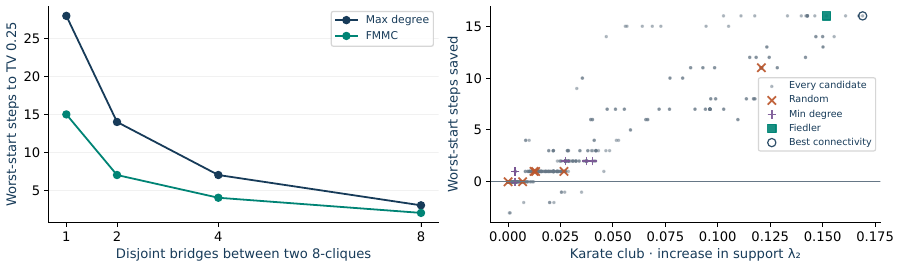

Families (report measurements)


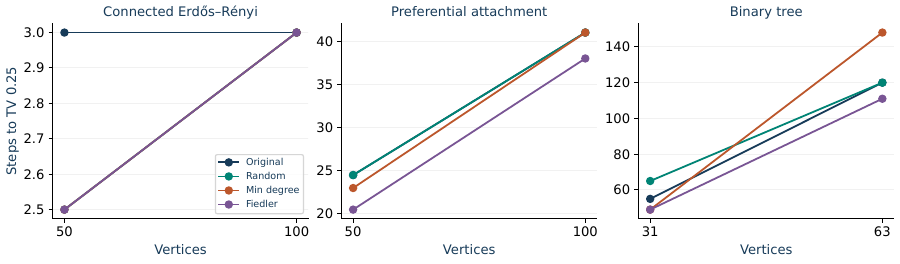

Method Scaling (report measurements)


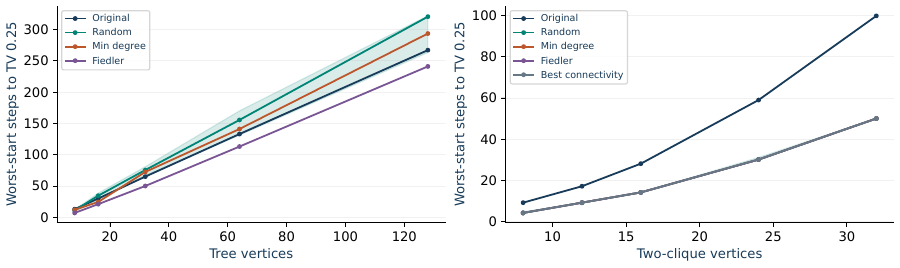

In [8]:
show_table("bridge-count", [
    {"Bridge graph": r["study"], "Weights": labels[r["method"]], "Steps": r["steps"]}
    for r in tv_rows("bridge-count")
])
tree = (csv_rows(OUT / "link-policies/link-policy-summary.csv") if mode == "full"
        else csv_rows(root / "results/aditi/summary.csv"))
show_table("tree-link-policies", [
    {"Link": policy_labels[r["policy"]], "Trials": int(r["trials"]),
     "Mean steps saved": round(float(r["mean_steps_saved"]), 1),
     "Slower trials": int(r["slower_trials"])}
    for r in tree if r.get("family", r.get("study")) in {"Tree", "Binary tree"}
])
figures("edges", "families", "method-scaling")

## Real networks

> **Student credit** · Glasgow uses Caroline’s clockwise shortcut and Danielle’s optimized weights. The nested network comparison also tests Aditi’s Fiedler rule.

The Glasgow Subway graph connects consecutive stations on the 15-station Outer Circle. We added one hypothetical link between Kinning Park and Cowcaddens, then tested the same four walks on the original and edited graph. Read across a row to see what the link changed for one walk. Three walks improved, while optimized weights went from 14 to 16 steps even after recalculating those weights. [SPT station data](https://www.spt.co.uk/travel-with-spt/subway/maps-stations/)

The full Western States power grid used the same 32 sampled starts for maximum degree and Metropolis. Their sample maxima were 28,515 and 7,721 steps. In the nested grid sweep we grew six connected samples, keeping all original links between selected vertices. At 96 vertices, maximum degree ranged from 289 to 584 steps, and a Fiedler edit lowered the median from 395 to 270. These ranges describe the sampled starts or graphs under the stated design.

| Walk | Original (steps) | With shortcut (steps) |
| --- | --- | --- |
| Clockwise | 43 | 20 |
| Maximum degree | 43 | 16 |
| Metropolis | 43 | 21 |
| Optimized weights | 14 | 16 |

Glasgow Map (replay)


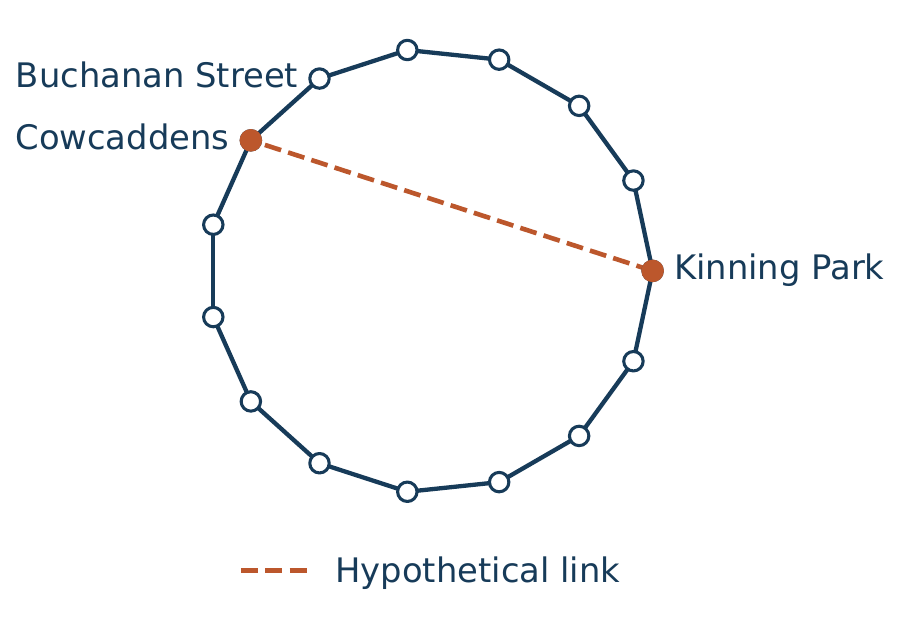

Full power-grid table: report measurements


| Walk | Sample maximum (steps) | Sample median (steps) |
| --- | --- | --- |
| Maximum degree | 28515 | 18797.5 |
| Metropolis | 7721 | 5154.5 |

Nested Map (report measurements)


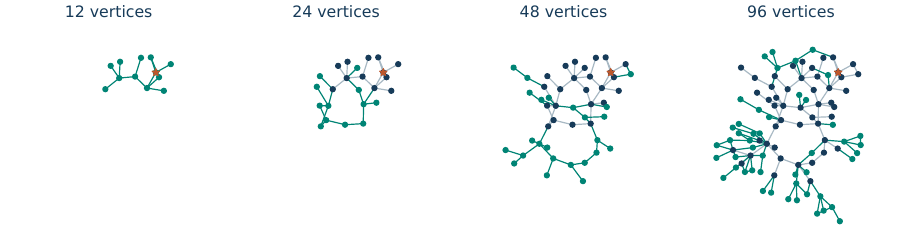

Nested (report measurements)


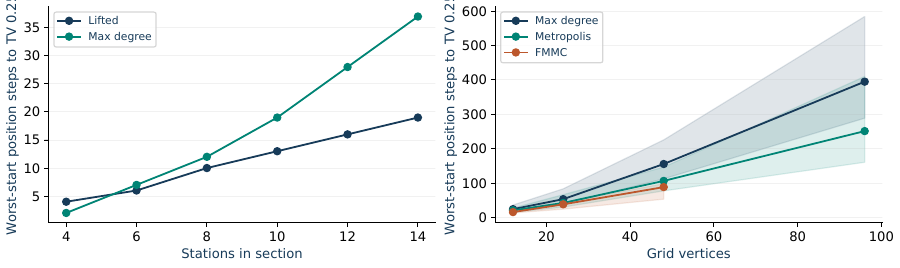

In [9]:
glasgow = {(r["method"], r["edge"] is not None): r["steps"] for r in tv_rows("real-networks")
           if r["vertices"] == 15}
show_table("glasgow-shortcut", [
    {"Walk": labels[key], "Original (steps)": glasgow[key, False],
     "With shortcut (steps)": glasgow[key, True]}
    for key in ("clockwise", "max_degree", "metropolis", "fmmc")
])
figures("glasgow-map")

if mode == "full":
    power = [(labels[r["method"]], r["steps"], r["start_median"]) for r in tv_rows("power-grid")]
else:
    power = [("Maximum degree", 28515, 18797.5), ("Metropolis", 7721, 5154.5)]
print("Full power-grid table:", "replay" if mode == "full" else "report measurements")
show_table("power-grid-starts", [
    {"Walk": method, "Sample maximum (steps)": largest, "Sample median (steps)": typical}
    for method, largest, typical in power
])
figures("nested-map", "nested")

## Sampling under equal work and equal time

> **Student credit** · These experiments compare sampling with Caroline’s ring shortcut, Dana’s direction memory, and Danielle’s optimized weights.

We estimated the probability of being in the first half of a 32-position network by counting visits to that half. The target is 50%. Root mean squared error measures how far the repeated estimates are from the known target. The steady-state experiment started at the target distribution and gave each trajectory 20,000 steps. The timed experiment used five paired runs at 10 and 60 seconds, charging setup time, and checked both half-network visits and visits to a single vertex.

A faster-mixing walk can still produce a noisier estimate because consecutive observations affect the accuracy of their average. The ring shortcut raised the first-half steady-state error from about 0.37 to 1.02 percentage points. In the recorded timed runs it also raised both ring errors. Direction memory helped both timed estimates on the line. The small timed sample limits how precisely we can rank close results.

Timed errors in percentage points: report measurements


| Walk | Half at 10 s | Half at 60 s | One vertex at 10 s | One vertex at 60 s |
| --- | --- | --- | --- | --- |
| Ordinary line | 0.0407 | 0.0151 | 0.00495 | 0.00284 |
| Lifted line | 0.00688 | 0.00291 | 0.000706 | 0.000435 |
| Clockwise ring | 0.00447 | 0.00175 | 0.00117 | 0.000324 |
| Ring with shortcut | 0.0159 | 0.00441 | 0.00167 | 0.000379 |

Mcmc (report measurements)


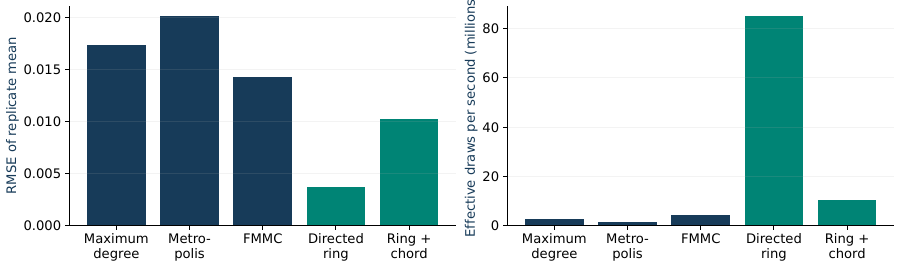

Budget (report measurements)


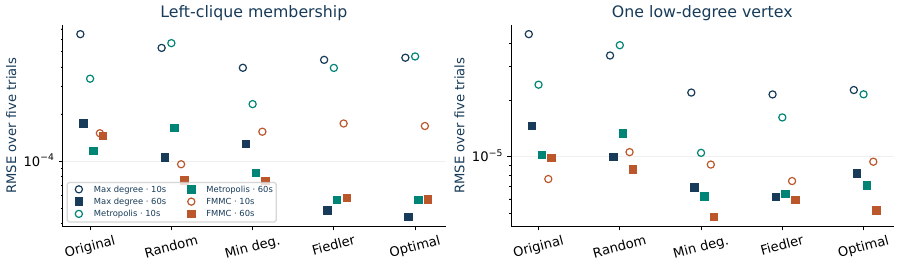

In [10]:
if run_timed:
    budget = csv_rows(OUT / "wall-budget/budget-comparison.csv")
    table_rows = [
        {"Walk": labels[r["method"]], "Graph": r["study"],
         "Link": policy_labels.get(r["policy"], r["policy"]),
         "Quantity": r["observable"], "Seconds": float(r["budget_seconds"]),
         "RMSE (percentage points)": round(100 * float(r["rmse"]), 7) if r["rmse"] else "Unavailable"}
        for r in budget if r["study"] == "Lifted path"
        or (r["study"] == "Cycle shortcut" and r["method"] == "clockwise")
    ]
else:
    figures_values = [
        ("Ordinary line", .0407, .0151, .00495, .00284),
        ("Lifted line", .00688, .00291, .000706, .000435),
        ("Clockwise ring", .00447, .00175, .00117, .000324),
        ("Ring with shortcut", .0159, .00441, .00167, .000379),
    ]
    columns = ["Walk", "Half at 10 s", "Half at 60 s", "One vertex at 10 s", "One vertex at 60 s"]
    table_rows = [dict(zip(columns, row, strict=True)) for row in figures_values]
print("Timed errors in percentage points:", "replay" if run_timed else "report measurements")
show_table("timed-estimation", table_rows)
figures("mcmc", "budget")

## Comparison summary and saved files

The most informative comparisons hold the graph and target constant and change one feature at a time. Reweighting helped the slowest starts on karate. Heading memory made the strongest difference on longer lines. Link placement mattered on rings, and connectivity alone could not distinguish good and poor ring shortcuts. If the goal is a sampling estimate, the error of that estimate under the available budget is the relevant comparison.

Below is the location of the test logs, JUnit output, CSV tables, vector plots and PNG previews. Each replayed preset also has its own folder with a manifest and the individual run records. Full mode adds the combined inventory, case comparisons and independent-reference results. For a portable readable copy of the outputs, save the notebook after running it or use the [headless command in the README](../README.md#report-and-notebook-workflow).

In [11]:
print(f"Saved results to {os.path.relpath(OUT, root)}")
print("Tests: build.log, release-tests.log, tests.xml, tables/test-results.csv")
print("Measurements: riffle.csv and one directory per replayed preset")
print("Review tables and plots: tables/, figures/report/, figures/replayed/, figures/tests/")
if mode == "full":
    print("Full results: inventory.csv, comparisons/, dana-parity.csv, student-parity.json")

Saved results to results/notebook/review
Tests: build.log, release-tests.log, tests.xml, tables/test-results.csv
Measurements: riffle.csv and one directory per replayed preset
Review tables and plots: tables/, figures/report/, figures/replayed/, figures/tests/
